In [1]:
import sys; sys.path.append("..")
from src.dataset import make_splits
train_df, val_df, test_df, classes = make_splits()
print(len(train_df), len(val_df), len(test_df))
print(test_df["label"].value_counts())

10164 2178 2178
label
Tomato___Tomato_Yellow_Leaf_Curl_Virus           643
Tomato___Bacterial_spot                          255
Tomato___Late_blight                             229
Tomato___Septoria_leaf_spot                      212
Tomato___Spider_mites Two-spotted_spider_mite    201
Tomato___healthy                                 190
Tomato___Target_Spot                             169
Tomato___Early_blight                            120
Tomato___Leaf_Mold                               114
Tomato___Tomato_mosaic_virus                      45
Name: count, dtype: int64


In [2]:
import os
print(os.getcwd())

D:\projects\plant-disease-detector


torch.Size([16, 3, 224, 224]) -2.1179039478302 2.640000104904175


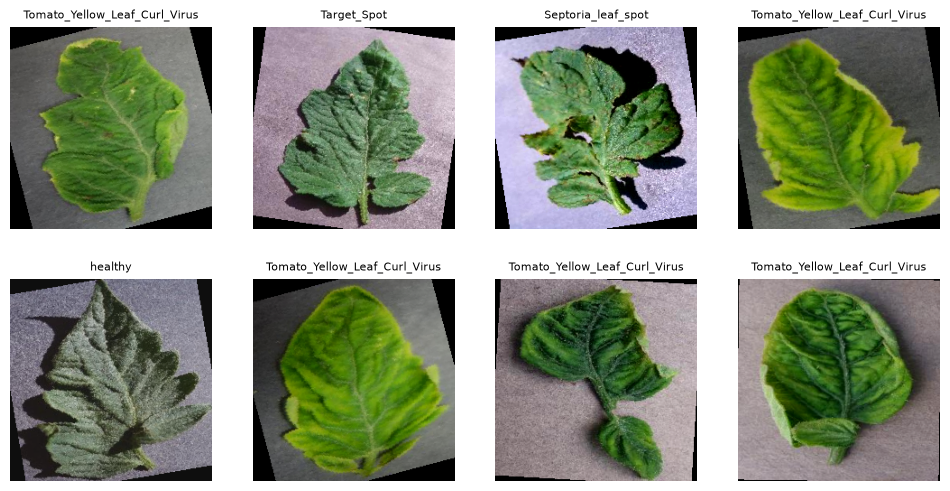

In [3]:
import sys; sys.path.append("..")
import matplotlib.pyplot as plt, torch
from src.dataset import load_splits, make_loaders, MEAN, STD, SPLIT_DIR

train_df, val_df, test_df = load_splits()
classes = (SPLIT_DIR / "classes.txt").read_text().split("\n")
train_loader, val_loader, test_loader = make_loaders(train_df, val_df, test_df)

x, y = next(iter(train_loader))
print(x.shape, x.min().item(), x.max().item())

mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, lab in zip(axes.flat, x[:8], y[:8]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(classes[lab].replace("Tomato___", ""), fontsize=8)
    ax.axis("off")
plt.show()

In [4]:
from torch.utils.data import DataLoader
from src.dataset import LeafDataset, eval_tf
from src.model import BaselineCNN
from src.train import set_seed, fit

set_seed(42)
tiny = DataLoader(LeafDataset(train_df.sample(64, random_state=0), eval_tf),
                  batch_size=16, shuffle=True)
model = BaselineCNN(num_classes=len(classes))
_ = fit(model, tiny, tiny, epochs=25, lr=1e-3, patience=99, ckpt="tiny_test.pt")

ep 01 | train loss 2.121 acc 0.266 | val loss 2.274 acc 0.281 f1 0.069
ep 02 | train loss 1.621 acc 0.516 | val loss 2.138 acc 0.266 f1 0.042
ep 03 | train loss 1.422 acc 0.562 | val loss 1.988 acc 0.266 f1 0.042
ep 04 | train loss 1.335 acc 0.594 | val loss 1.894 acc 0.266 f1 0.042
ep 05 | train loss 1.155 acc 0.641 | val loss 1.803 acc 0.297 f1 0.071
ep 06 | train loss 1.133 acc 0.719 | val loss 1.684 acc 0.422 f1 0.143
ep 07 | train loss 1.073 acc 0.688 | val loss 1.496 acc 0.516 f1 0.184
ep 08 | train loss 0.985 acc 0.734 | val loss 1.353 acc 0.578 f1 0.206
ep 09 | train loss 0.939 acc 0.812 | val loss 1.256 acc 0.594 f1 0.209
ep 10 | train loss 0.930 acc 0.734 | val loss 1.085 acc 0.625 f1 0.272
ep 11 | train loss 0.994 acc 0.734 | val loss 1.080 acc 0.688 f1 0.298
ep 12 | train loss 0.825 acc 0.812 | val loss 0.941 acc 0.703 f1 0.340
ep 13 | train loss 0.903 acc 0.734 | val loss 0.932 acc 0.688 f1 0.349
ep 14 | train loss 0.922 acc 0.750 | val loss 0.749 acc 0.766 f1 0.401
ep 15 

In [5]:
import time
set_seed(42)
model = BaselineCNN(num_classes=len(classes))
t = time.time()
history = fit(model, train_loader, val_loader, epochs=1)
print(f"{time.time() - t:.0f} s per epoch")

ep 01 | train loss 1.126 acc 0.628 | val loss 0.698 acc 0.757 f1 0.691
1101 s per epoch


In [6]:
import time, torch
from src.model import BaselineCNN

it = iter(train_loader)
t = time.time()
for _ in range(20):
    x, y = next(it)
print(f"data : {(time.time() - t) / 20:.2f} s/batch")

model = BaselineCNN(len(classes))
opt = torch.optim.Adam(model.parameters())
crit = torch.nn.CrossEntropyLoss()
t = time.time()
for _ in range(5):
    loss = crit(model(x), y); opt.zero_grad(); loss.backward(); opt.step()
print(f"model: {(time.time() - t) / 5:.2f} s/batch")
print("threads:", torch.get_num_threads())

data : 0.18 s/batch
model: 1.61 s/batch
threads: 2


In [ ]:
set_seed(42)
model = BaselineCNN(num_classes=len(classes))
t = time.time()
history = fit(model, train_loader, val_loader, epochs=1, ckpt="baseline_128.pt")
print(f"{time.time() - t:.0f} s per epoch")